# Can we predict which trials will stop early?

If a trial's risk of termination could be estimated **at registration**, sponsors, ethics committees and funders could act early: plan recruitment better, add sites, or rethink the design.

1. Set up an honest test: only information known at registration, and a time-based split
2. A trap: data leakage through enrollment
3. Compare models: design features, text, both
4. What drives the predictions?
5. How useful is it? Risk groups

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import rankdata
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=UserWarning)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT / "src"))
import style
style.apply()

FIG = ROOT / "figures"
def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", dpi=120)

trials = pd.read_parquet(ROOT / "data" / "processed" / "trials.parquet")
y = trials["terminated"].to_numpy()

## 1. An honest test

**Only information known at registration.** We use the trial's design and plan: phase, sponsor type, collaborators, randomisation, blinding, number of arms and outcomes, eligibility (ages, healthy volunteers, length of the criteria), number of sites and countries, intervention types, disease areas, and whether there is a data monitoring committee.
We **exclude** anything that is only known *after* the trial runs: actual enrollment, actual completion dates, and whether results were posted.

⚠️ ClinicalTrials.gov shows each trial's **latest** record, not the version at registration. Some fields, such as the list of sites, may have been updated during the trial. That makes even this setup slightly optimistic.

**Time-based split.** We train on trials that **started 2008–2015** and test on trials that **started 2016–2019**. This mimics real use: learn from the past, predict the future.

In [2]:
CATEGORICAL = ["phase", "sponsor", "allocation", "intervention_model", "purpose", "masking", "sex", "has_dmc"]
NUMERIC = (["n_collaborators", "industry_collaborator", "n_arms", "n_interventions", "n_primary_outcomes",
            "n_secondary_outcomes", "healthy_volunteers", "min_age", "max_age", "criteria_words",
            "n_locations", "n_countries", "us_site", "n_conditions"]
           + [c for c in trials if c.startswith("iv_")] + [c for c in trials if c.startswith("area_")])

train = (trials["start_year"] <= 2015).to_numpy()
test = ~train
print(f"Train: {train.sum():,} trials (2008–2015), {y[train].mean():.1%} terminated")
print(f"Test:  {test.sum():,} trials (2016–2019), {y[test].mean():.1%} terminated")

def tabular_model(numeric):
    prep = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20, sparse_output=False), CATEGORICAL),
        ("num", "passthrough", numeric),
    ])
    return make_pipeline(prep, HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=0))

def linear_model(numeric):
    prep = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20), CATEGORICAL),
        ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), numeric),
    ])
    return make_pipeline(prep, LogisticRegression(max_iter=3000, class_weight="balanced"))

def score(p):
    return {"ROC-AUC": roc_auc_score(y[test], p), "AP": average_precision_score(y[test], p)}

Train: 32,844 trials (2008–2015), 15.5% terminated
Test:  14,067 trials (2016–2019), 18.7% terminated


## 2. A trap: enrollment leaks the answer

The registry's **enrollment** field shows how many patients *actually* took part. A trial that stops early has, by definition, fewer patients than planned. Termination rate by enrollment size:

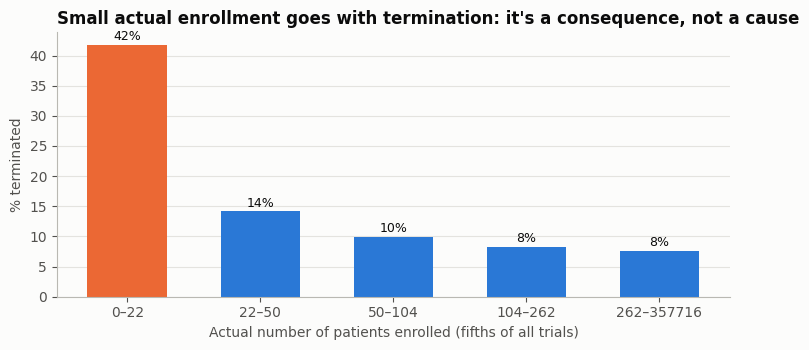

In [3]:
bins = pd.qcut(trials["enrollment"], 5)
by_size = trials.groupby(bins, observed=True)["terminated"].mean()
labels = [f"{int(max(i.left, 0))}–{int(i.right)}" for i in by_size.index]

fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.bar(labels, by_size * 100, color=[style.ORANGE] + [style.BLUE] * 4, width=0.6)
for i, v in enumerate(by_size):
    ax.text(i, v * 100 + 0.8, f"{v:.0%}", ha="center", fontsize=9)
ax.set(xlabel="Actual number of patients enrolled (fifths of all trials)", ylabel="% terminated",
       title="Small actual enrollment goes with termination: it's a consequence, not a cause")
ax.grid(axis="x", visible=False)
save_fig("08_enrollment_leak")
plt.show()

In [4]:
honest = tabular_model(NUMERIC).fit(trials[train], y[train])
p_tab = honest.predict_proba(trials[test])[:, 1]
leaky = tabular_model(NUMERIC + ["enrollment"]).fit(trials[train], y[train])
p_leak = leaky.predict_proba(trials[test])[:, 1]
pd.DataFrame({"Registration-time features": score(p_tab), "… plus actual enrollment (leak)": score(p_leak)}).round(3)

,Registration-time features,… plus actual enrollment (leak)
ROC-AUC,0.685,0.817
AP,0.329,0.588


Adding actual enrollment raises ROC-AUC from about **0.69 to 0.82**. But this "improvement" is useless in practice: at registration nobody knows how many patients a trial will end up with.
**Leakage like this is one of the most common mistakes in applied machine learning.** The model looks excellent on paper and fails in real use. From here on, enrollment is excluded.

## 3. Comparing models

In [5]:
p_lin = linear_model(NUMERIC).fit(trials[train], y[train]).predict_proba(trials[test])[:, 1]

text = (trials["title"].fillna("") + " " + trials["summary"].fillna("") + " "
        + trials["conditions"].fillna("") + " " + trials["keywords"].fillna(""))
tfidf = TfidfVectorizer(min_df=5, max_features=50_000, ngram_range=(1, 2), sublinear_tf=True, stop_words="english")
X_text_train = tfidf.fit_transform(text[train])
text_model = LogisticRegression(C=1.0, max_iter=3000, class_weight="balanced").fit(X_text_train, y[train])
p_text = text_model.predict_proba(tfidf.transform(text[test]))[:, 1]

p_blend = (rankdata(p_tab) + rankdata(p_text)) / (2 * len(p_tab))  # average the two models' rankings

results = pd.DataFrame({
    "Logistic regression · design": score(p_lin),
    "Gradient boosting · design": score(p_tab),
    "Logistic regression · text": score(p_text),
    "Blend · design + text": score(p_blend),
}).T
results["AP / base rate"] = results["AP"] / y[test].mean()
results.round(3)

,ROC-AUC,AP,AP / base rate
Logistic regression · design,0.657,0.289,1.551
Gradient boosting · design,0.685,0.329,1.762
Logistic regression · text,0.657,0.285,1.529
Blend · design + text,0.697,0.332,1.780


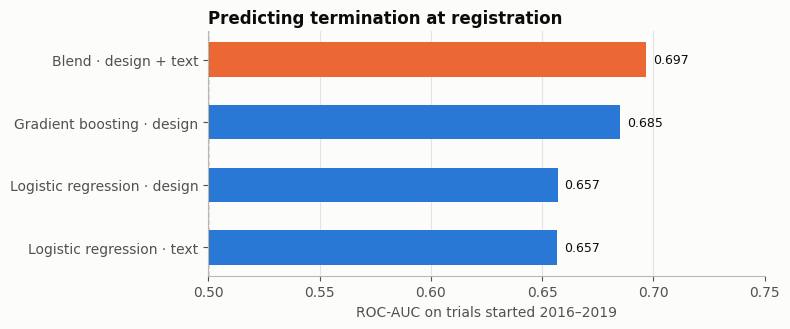

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.4))
r = results.sort_values("ROC-AUC")
ax.barh(r.index, r["ROC-AUC"], color=[style.ORANGE if "Blend" in i else style.BLUE for i in r.index], height=0.55)
for i, v in enumerate(r["ROC-AUC"]):
    ax.text(v + 0.003, i, f"{v:.3f}", va="center", fontsize=9)
ax.axvline(0.5, color=style.TEXT_2, lw=1, ls="--")
ax.set(xlim=(0.5, 0.75), xlabel="ROC-AUC on trials started 2016–2019", title="Predicting termination at registration")
ax.grid(axis="y", visible=False)
save_fig("09_model_comparison")
plt.show()

- All models do **better than chance, but only moderately** (ROC-AUC about 0.65–0.70).
- Gradient boosting on design features beats logistic regression, so the relationships are not simply linear.
- Text alone is weaker than design features, and blending both gives a small gain.

This is a realistic and important result: **most of what makes a trial stop happens after registration.** Recruitment problems, business decisions and funding cuts are hard to foresee from a trial's description.

## 4. What drives the predictions?

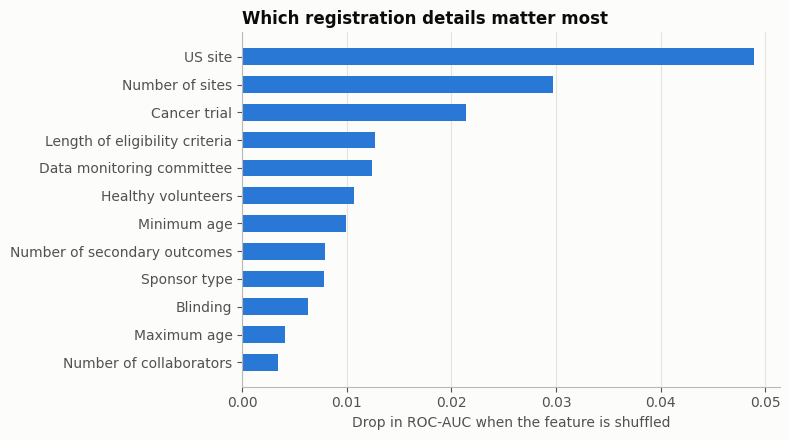

In [7]:
imp = permutation_importance(honest, trials.loc[test, CATEGORICAL + NUMERIC], y[test], scoring="roc_auc", n_repeats=5, random_state=0, n_jobs=-1)
importance = (pd.Series(imp.importances_mean, index=CATEGORICAL + NUMERIC)
              .sort_values(ascending=False).head(12).sort_values())
nice = {"n_locations": "Number of sites", "criteria_words": "Length of eligibility criteria",
        "n_secondary_outcomes": "Number of secondary outcomes", "phase": "Phase", "sponsor": "Sponsor type",
        "has_dmc": "Data monitoring committee", "masking": "Blinding", "allocation": "Randomisation",
        "n_countries": "Number of countries", "max_age": "Maximum age", "min_age": "Minimum age",
        "n_primary_outcomes": "Number of primary outcomes", "area_Cancer": "Cancer trial",
        "healthy_volunteers": "Healthy volunteers", "n_arms": "Number of arms", "purpose": "Primary purpose",
        "n_conditions": "Number of conditions", "intervention_model": "Intervention model",
        "n_collaborators": "Number of collaborators", "us_site": "US site", "iv_drug": "Drug intervention",
        "n_interventions": "Number of interventions", "area_Infections": "Infection trial", "sex": "Sex eligibility"}

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh([nice.get(i, i) for i in importance.index], importance, color=style.BLUE, height=0.6)
ax.set(xlabel="Drop in ROC-AUC when the feature is shuffled", title="Which registration details matter most")
ax.grid(axis="y", visible=False)
save_fig("10_feature_importance")
plt.show()

In [8]:
us = trials.groupby(["us_site", "sponsor"])["terminated"].mean().unstack()[["Industry", "Academic / other"]]
us.index = ["No US site", "At least one US site"]
print("Termination rate (%) by US site and sponsor:")
print((us * 100).round(1).to_string())

sites = trials.groupby(pd.cut(trials["n_locations"], [-1, 0, 1, 5, 20, 100, 1e6],
                              labels=["none listed", "1", "2–5", "6–20", "21–100", "100+"]), observed=True)["terminated"].mean()
crit = trials.groupby(pd.qcut(trials["criteria_words"], 5), observed=True)["terminated"].mean()
print("\nTermination rate (%) by number of sites:")
print((sites * 100).round(1).to_string())
print("\nTermination rate (%) by length of eligibility criteria (fifths, in words):")
print((crit * 100).round(1).to_string())

Termination rate (%) by US site and sponsor:
sponsor               Industry  Academic / other
No US site                11.1              12.8
At least one US site      18.2              24.8

Termination rate (%) by number of sites:
n_locations
none listed    10.3
1              16.8
2–5            18.9
6–20           17.2
21–100         14.4
100+           15.2

Termination rate (%) by length of eligibility criteria (fifths, in words):
criteria_words
(-0.001, 106.0]    10.6
(106.0, 197.0]     15.3
(197.0, 330.0]     16.8
(330.0, 554.0]     18.7
(554.0, 2706.0]    20.9


**Where and how big.** The strongest single signal is whether a trial has **a site in the United States**: those trials terminate far more often (about 21% vs 12%), for industry and academic sponsors alike. Two explanations are likely, and both probably play a part:
- **Real differences:** US trials compete for patients in a crowded market, and commercial decisions are often taken there.
- **Reporting differences:** US law (FDAAA 801) requires sponsors to keep a trial's status up to date. Elsewhere, a trial that quietly stops often stays listed with an *unknown* status, and those trials are not in this dataset at all. So part of the gap may be **better reporting of terminations in the US**, not more failures.

Next come **number of sites**, **cancer**, the **length of the eligibility criteria** (longer, stricter criteria make recruitment harder: termination rises from 11% to 21% across the five length groups), a **data monitoring committee** and **healthy volunteers**.

Phase and sponsor type matter in notebook 01 but rank lower here. Their information overlaps with other features (blinding, monitoring committees, healthy volunteers), and permutation importance gives little credit to features that others can stand in for.

### What did the text model learn?

In [9]:
words = np.array(tfidf.get_feature_names_out())
coef = text_model.coef_[0]
print("Words most associated with TERMINATION:\n ", ", ".join(words[np.argsort(-coef)[:30]]))
print("\nWords most associated with COMPLETION:\n ", ", ".join(words[np.argsort(coef)[:30]]))

Words most associated with TERMINATION:
  cancer, tanezumab, melanoma, dutogliptin, brodalumab, treatment, mg daily, burn, pf, relative, observation, patients, tumor, ulcers, cancer pain, escitalopram, tumour, doxorubicin, growth hormone, ramelteon, evaluating efficacy, heparin, called, syndrome, criteria, label extension, hemorrhage, headache, proellex, pulmonary hypertension

Words most associated with COMPLETION:
  japanese, chinese, capsules, vaccine, healthy, adults, pharmacokinetics, efficacy safety, behavioral, exposure, stem cells, nivolumab, health, different, stem, cognition, patients mild, 24, biochemical, monthly, metastatic prostate, ramucirumab, influenza vaccine, conditions, antioxidant, vitro, multicenter phase, japan, gel, program


Some words are meaningful: *cancer*, *tumor* and *melanoma* point to oncology, while *healthy*, *vaccine* and *pharmacokinetics* point to simpler, low-risk trials.
But many top words are **drug names** (for example tanezumab, brodalumab or dutogliptin). Their development programmes were stopped, so *every* trial of that drug was terminated together.
The text model partly memorises **failed drug programmes**. That won't help with a new drug, which is another reason to read text-model performance with care.

## 5. How useful is it? Risk groups

Split the 2016–2019 test trials into ten equal groups by predicted risk (blend model) and compare their actual termination rates:

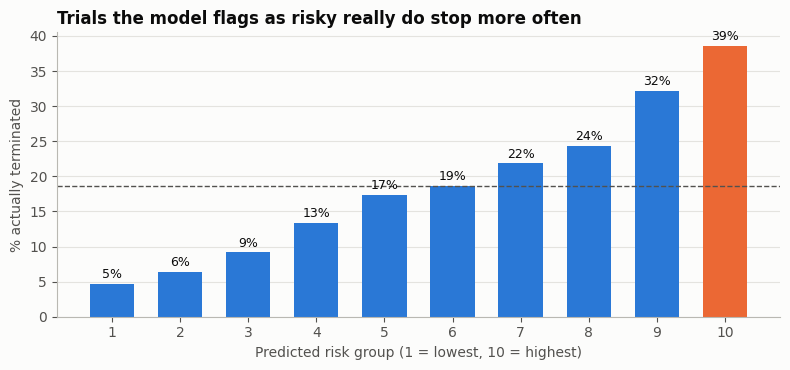

Lowest-risk tenth: 5% terminated · highest-risk tenth: 39% (8.2x)


In [10]:
decile = pd.qcut(p_blend, 10, labels=False) + 1
by_decile = pd.Series(y[test]).groupby(decile).mean()

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(by_decile.index, by_decile * 100, color=[style.BLUE] * 9 + [style.ORANGE], width=0.65)
for i, v in by_decile.items():
    ax.text(i, v * 100 + 0.8, f"{v:.0%}", ha="center", fontsize=9)
ax.axhline(y[test].mean() * 100, color=style.TEXT_2, lw=1, ls="--")
ax.set_xticks(range(1, 11))
ax.set(xlabel="Predicted risk group (1 = lowest, 10 = highest)", ylabel="% actually terminated",
       title="Trials the model flags as risky really do stop more often")
ax.grid(axis="x", visible=False)
save_fig("11_risk_deciles")
plt.show()
print(f"Lowest-risk tenth: {by_decile.iloc[0]:.0%} terminated · highest-risk tenth: {by_decile.iloc[-1]:.0%} "
      f"({by_decile.iloc[-1] / by_decile.iloc[0]:.1f}x)")

Even a modest model separates trials clearly: about **39%** of the riskiest tenth terminated, against **5%** of the safest tenth, roughly **8 times** more often.
In practice this could support a **review checklist**: funders or ethics committees could give extra scrutiny to recruitment plans for trials in the top risk groups.

## Conclusions
1. **Termination is only moderately predictable at registration** (ROC-AUC about 0.70). Most reasons (recruitment, business, funding) unfold later.
2. **Beware leakage.** Actual enrollment makes the model look much better (ROC-AUC 0.82), but it is only known after the fact.
3. The strongest signals are **a US site** (partly a reporting effect), **number of sites**, **cancer**, and **stricter eligibility criteria**.
4. Text models partly memorise **failed drug programmes**, which doesn't transfer to new drugs.
5. The model still separates **high- and low-risk** trials (39% vs 5% terminated), which is enough to prioritise reviews.

## Limitations and next steps
- The registry shows the latest version of each record, so some "registration-time" fields may have changed during the trial. The [ClinicalTrials.gov archive](https://clinicaltrials.gov/) of record versions could fix this.
- Trials whose status was never updated (*unknown status*) are excluded. They are more common outside the US and probably include many quiet terminations.
- The stopping reasons were grouped with keyword rules. A language model could classify them more accurately.
- **Next:** add planned (anticipated) enrollment from the first record version, model each termination reason separately, and use survival analysis for *when* trials stop.